# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Submitter
- **Email:** student@dicoding.org
- **ID Dicoding:** student_dicoding

## Menentukan Pertanyaan Bisnis (SMART Framework)
1. **Pertanyaan 1 (Specific & Measurable):** Bagaimana pengaruh kondisi cuaca (*weathersit*) terhadap rata-rata jumlah penyewaan sepeda harian selama periode tahun 2011-2012?
2. **Pertanyaan 2 (Action-Oriented & Time-bound):** Bagaimana perbedaan pola proporsi penggunaan sepeda antara pengguna kasual (*casual*) dan pengguna terdaftar (*registered*) pada hari kerja (*workingday*) dibandingkan akhir pekan/libur pada periode 2011-2012 untuk menentukan strategi promosi keanggotaan?

## Mengimpor Semua Package/Library yang Digunakan

In [16]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Library berhasil diimpor.")

Library berhasil diimpor.


## Data Wrangling

### Gathering Data
Memuat dataset `day.csv` ke dalam DataFrame.

In [23]:
day_df = pd.read_csv('data/day.csv')
day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt
0,2011-01-01,3,0,1,0,5,0,1,0.190345,0.424774,0.359242,270,4110,2582
1,2011-01-02,4,0,1,0,6,1,1,0.773660,0.325191,0.450047,394,4023,2071
2,2011-01-03,1,0,1,0,0,1,1,0.293785,0.587556,0.416208,288,4035,4943
3,2011-01-04,3,0,1,0,1,1,1,0.482608,0.409034,0.156443,525,1459,5483
4,2011-01-05,3,0,1,0,2,1,1,0.216157,0.745849,0.318233,1076,977,2911


### Assessing Data
Mengecek kualitas data: *missing values*, *duplicate data*, dan tipe data.

In [30]:
print("Info dataset:")
print("--------------------------------------")
day_df.info()
print("--------------------------------------")
print("\n======================================")
print("\nJumlah Missing Values:") 
print(day_df.isnull().sum())
print("======================================")
print("\nxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")
print("\nJumlah Duplikasi:", day_df.duplicated().sum())
print("xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx")

Info dataset:
--------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   dteday         731 non-null    datetime64[us]
 1   season         731 non-null    int64         
 2   yr             731 non-null    int64         
 3   mnth           731 non-null    int64         
 4   holiday        731 non-null    int64         
 5   weekday        731 non-null    int64         
 6   workingday     731 non-null    int64         
 7   weathersit     731 non-null    int64         
 8   temp           731 non-null    float64       
 9   hum            731 non-null    float64       
 10  windspeed      731 non-null    float64       
 11  casual         731 non-null    int64         
 12  registered     731 non-null    int64         
 13  cnt            731 non-null    int64         
 14  season_label   731 non-null    s

**Hasil Dari Assessing Data:**
1. Tipe data untuk kolom `dteday` masih berbentuk `str`  (sehingga harus diubah dahulu ke `datetime` untuk analisis waktu).
2. Tidak menemukan *missing values* maupun data yang terduplikasi (*duplicates*).
3. Beberapa kolom bertype angka seperti `season` dan `weathersit` perlu di ubah dari angkan ke kategori cuaca untuk kemudahan interpretasi.

### Cleaning Data
Melakukan perbaikan tipe data dan mapping label.

In [28]:
# Mengubah tipe data dteday
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# Mapping label musim dan cuaca
season_map = {1: 'Musim Semi', 2: 'Musim Panas', 3: 'Musim Gugur', 4: 'Musim Dingin'}
weather_map = {1: 'Cerah/Berawan', 2: 'Mendung/Kabut', 3: 'Hujan/Salju Ringan', 4: 'Hujan Lebat'}

day_df['season_label'] = day_df['season'].map(season_map)
day_df['weather_label'] = day_df['weathersit'].map(weather_map)

day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt,season_label,weather_label
0,2011-01-01,3,0,1,0,5,0,1,0.190345,0.424774,0.359242,270,4110,2582,Musim Gugur,Cerah/Berawan
1,2011-01-02,4,0,1,0,6,1,1,0.773660,0.325191,0.450047,394,4023,2071,Musim Dingin,Cerah/Berawan
2,2011-01-03,1,0,1,0,0,1,1,0.293785,0.587556,0.416208,288,4035,4943,Musim Semi,Cerah/Berawan
3,2011-01-04,3,0,1,0,1,1,1,0.482608,0.409034,0.156443,525,1459,5483,Musim Gugur,Cerah/Berawan
4,2011-01-05,3,0,1,0,2,1,1,0.216157,0.745849,0.318233,1076,977,2911,Musim Gugur,Cerah/Berawan


## Exploratory Data Analysis (EDA)

### Eksplorasi 1: Pengaruh Cuaca terhadap Total Penyewaan

In [31]:
weather_summary = day_df.groupby('weather_label').agg({
    'cnt': ['mean', 'max', 'min', 'std']
}).reset_index()
weather_summary

weather_label          cnt                        
                              mean   max  min          std
0       Cerah/Berawan  3287.906818  5968  612  1600.185024
1  Hujan/Salju Ringan  3256.492308  5743  700  1491.277526
2       Mendung/Kabut  3415.584071  5935  628  1489.262115

### Eksplorasi 2: Perbandingan Pengguna Kasual vs Terdaftar pada Hari Kerja vs Libur

In [32]:
workingday_summary = day_df.groupby('workingday').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': 'mean'
}).reset_index()
workingday_summary['workingday'] = workingday_summary['workingday'].map({0: 'Akhir Pekan/Libur', 1: 'Hari Kerja'})
workingday_summary

,workingday,casual,registered,cnt
0,Akhir Pekan/Libur,750.192661,2549.743119,3282.775229
1,Hari Kerja,844.986355,2497.081871,3342.354776


### Analisis Lanjutan: Binning Suhu (Clustering Sederhana)

In [33]:
day_df['temp_category'] = pd.cut(day_df['temp'], bins=[0, 0.3, 0.6, 1.0], labels=['Dingin', 'Sedang', 'Panas'])
day_df.groupby('temp_category')['cnt'].mean().reset_index()

,temp_category,cnt
0,Dingin,3161.261905
1,Sedang,3402.904412
2,Panas,3345.673540


## Visualization & Explanatory Analysis

### Visualisasi Pertanyaan 1: Pengaruh Kondisi Cuaca

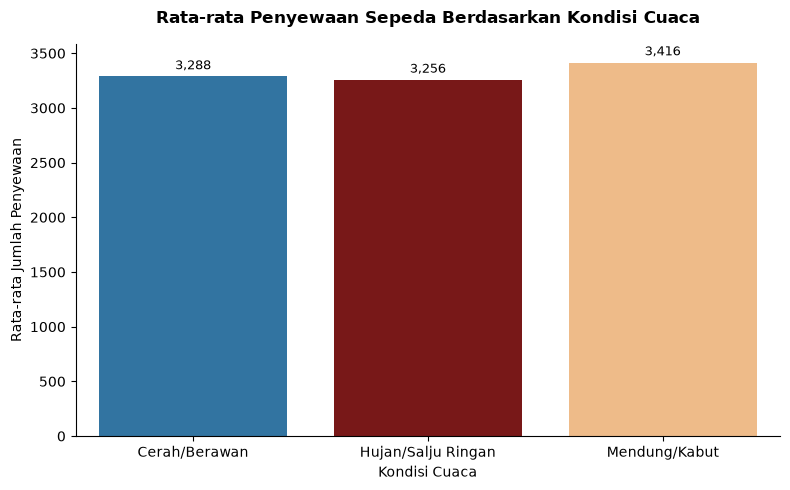

In [39]:
plt.figure(figsize=(8, 5))
custom_palette = [
    '#1f77b4', 
    '#880808',
    '#ffbb78',
]
ax = sns.barplot(
    data=day_df,
    x='weather_label',
    y='cnt',
    hue='weather_label',  
    palette=custom_palette,
    errorbar=None,  
    legend=False,  
)

plt.title(
    'Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca',
    fontsize=12,
    weight='bold',
    pad=15,
)
plt.xlabel('Kondisi Cuaca', fontsize=10)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=10)

 
for p in ax.patches:
  ax.annotate(
      f'{p.get_height():,.0f}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=9,
      xytext=(0, 3),
      textcoords='offset points',
  )

sns.despine()
plt.tight_layout()
plt.show()

### Visualisasi Pertanyaan 2: Pengguna Kasual vs Terdaftar

          workingday      casual   registered
0  Akhir Pekan/Libur  750.192661  2549.743119
1         Hari Kerja  844.986355  2497.081871
-----------------------------------------------------------------------



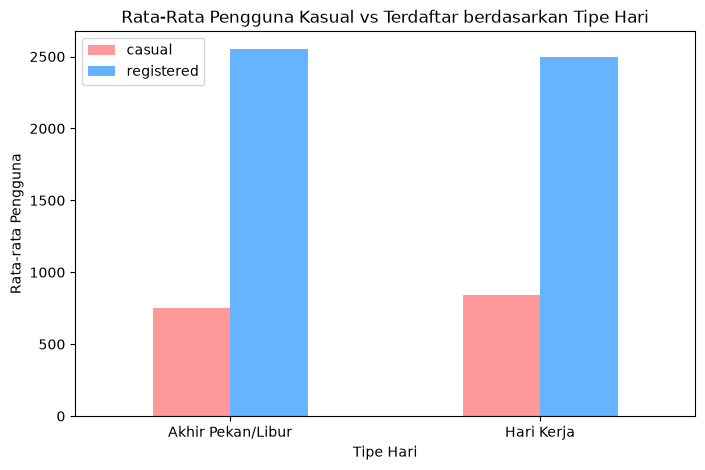

In [42]:
workingday_df = day_df.groupby('workingday')[['casual', 'registered']].mean().reset_index()
workingday_df['workingday'] = workingday_df['workingday'].map({0: 'Akhir Pekan/Libur', 1: 'Hari Kerja'})
print(workingday_df)
print("-----------------------------------------------------------------------\n")
workingday_df.set_index('workingday').plot(kind='bar', figsize=(8, 5), color=['#ff9999','#66b3ff'])
plt.title('Rata-Rata Pengguna Kasual vs Terdaftar berdasarkan Tipe Hari')
plt.xlabel('Tipe Hari')
plt.ylabel('Rata-rata Pengguna')
plt.xticks(rotation=0)
plt.show()

## Conclusion & Recommendation

### Kesimpulan
1. **Kondisi Cuaca:** Kondisi cuaca cerah/berawan menghasilkan tingkat penyewaan sepeda tertinggi. Penurunan drastis terjadi saat cuaca memburuk (hujan/salju).
2. **Pola Pengguna:** Pengguna terdaftar (*registered*) mendominasi penyewaan pada hari kerja dan hari libur (digunakan untuk transportasi rutin/bekerja serta kemungkinan rekreasi), sedangkan pengguna kasual (*casual*) meningkat signifikan pada  hari kerja (ini berarti digunakan untuk keperluan tansportasi untuk bekerja).

### Rekomendasi (Action Items)
- **Strategi Pemasaran Konversi:** Berikan promosi diskon pendaftaran keanggotaan/langganan bagi pengguna *casual* pada hari kerja untuk mendorong mereka menjadi *registered user*.
- **Manajemen Operasional:** Lakukan pemeliharaan armada sepeda (*maintenance*) pada hari-hari dengan prediksi cuaca buruk untuk meminimalkan kendala teknis saat permintaan tinggi di cuaca cerah.